<a href="https://colab.research.google.com/github/Andrew-Lever/Programming-BigDataAnalytics/blob/main/Assignment_3/2_05_Spotify_Exploratory_Data_Analysis_COMPLETED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1vv_PsWBnUJwSCkwKDoJAC-vXjtaEA4Ts)

# Spotify Exploratory Data Analysis (EDA)


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving spotify.csv to spotify.csv


We can now import the data into pandas as before:

In [25]:
spotify = pd.read_csv('spotify.csv')
spotify.head()

,user_id,age,country,subscription_type,listening_time,songs_played_per_day,skip_rate,device_type,ads_listened_per_week,offline_listening,is_churned
0,1,54,CA,Free,26,23,0.20,Desktop,31,0,1
1,2,33,DE,Family,141,62,0.34,Web,0,1,0
2,3,38,AU,Premium,199,38,0.04,Mobile,0,1,1
3,4,22,CA,Student,36,2,0.31,Mobile,0,1,0
4,5,29,US,Family,250,57,0.36,Mobile,0,1,1


We can find the number of rows and columns with ".shape":

In [26]:
spotify.shape

(8000, 11)

We can get informtaion about the data using the _info_ function:

In [27]:
spotify.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                8000 non-null   int64  
 1   age                    8000 non-null   int64  
 2   country                8000 non-null   object 
 3   subscription_type      8000 non-null   object 
 4   listening_time         8000 non-null   int64  
 5   songs_played_per_day   8000 non-null   int64  
 6   skip_rate              8000 non-null   float64
 7   device_type            8000 non-null   object 
 8   ads_listened_per_week  8000 non-null   int64  
 9   offline_listening      8000 non-null   int64  
 10  is_churned             8000 non-null   int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 687.6+ KB


There is no missing data, however, we must investigate further.

In [28]:
spotify.isnull().sum()

,0
user_id,0
age,0
country,0
subscription_type,0
listening_time,0
songs_played_per_day,0
skip_rate,0
device_type,0
ads_listened_per_week,0
offline_listening,0


In [30]:
# Percent of data which is not available
spotify.isnull().sum()/len(spotify) * 100

,0
user_id,0.0
age,0.0
country,0.0
subscription_type,0.0
listening_time,0.0
songs_played_per_day,0.0
skip_rate,0.0
device_type,0.0
ads_listened_per_week,0.0
offline_listening,0.0


In [31]:
spotify.duplicated().value_counts()

,count
False,8000


There is no evidence of missing data, therefore we can continue with the exploratory analysis. Starting with the statistics:

In [32]:
spotify.describe()

,user_id,age,listening_time,songs_played_per_day,skip_rate,ads_listened_per_week,offline_listening,is_churned
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,4000.50000,37.662125,154.068250,50.127250,0.300127,6.943875,0.747750,0.258875
std,2309.54541,12.740359,84.015596,28.449762,0.173594,13.617953,0.434331,0.438044
min,1.00000,16.000000,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2000.75000,26.000000,81.000000,25.000000,0.150000,0.000000,0.000000,0.000000
50%,4000.50000,38.000000,154.000000,50.000000,0.300000,0.000000,1.000000,0.000000
75%,6000.25000,49.000000,227.000000,75.000000,0.450000,5.000000,1.000000,1.000000
max,8000.00000,59.000000,299.000000,99.000000,0.600000,49.000000,1.000000,1.000000


We can see that only three of the columns have been "described" ... the three that were numeric (int64). For each, we get a range of useful measures including the mean average, the standard deviation, minimum and maximum values, and the 25th, 50th (median) and 75th percentyles.

### Visualising the Data

[]

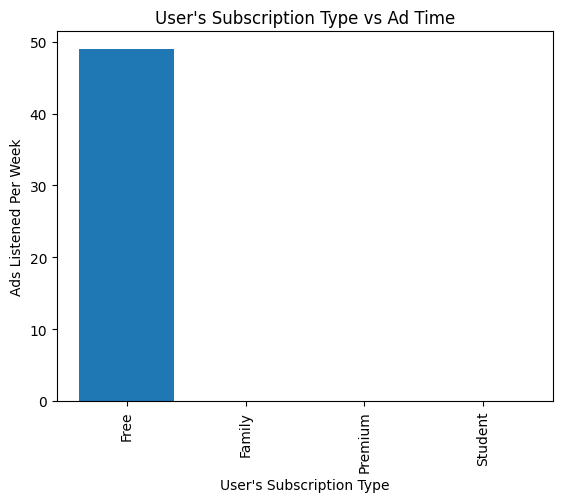

In [43]:
plt.bar(spotify['subscription_type'], spotify['ads_listened_per_week']) # create a bar chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('User\'s Subscription Type') # x-axis is parent's education level
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Ads Listened Per Week') # y-axis is maths score
plt.title('User\'s Subscription Type vs Ad Time') # add title
plt.plot() # plot the chart to screen

[]

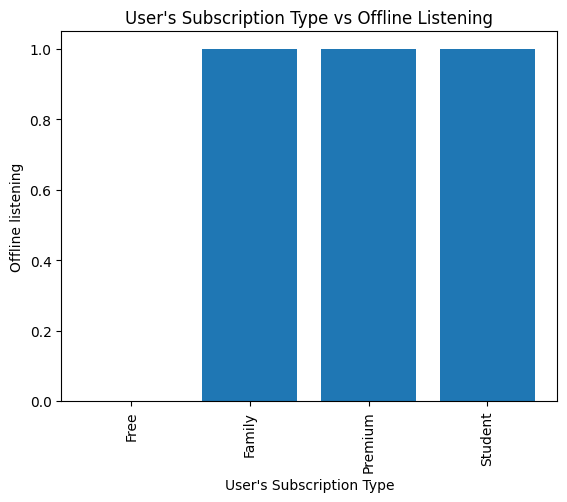

In [45]:
plt.bar(spotify['subscription_type'], spotify['offline_listening']) # create a bar chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('User\'s Subscription Type') # x-axis is parent's education level
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Offline listening') # y-axis is maths score
plt.title('User\'s Subscription Type vs Offline Listening') # add title
plt.plot() # plot the chart to screen

As expected, those with 'Free' accounts must watch advertisements and are unable to listen to music without an internet connection. However, let us investigate deeper.

[]

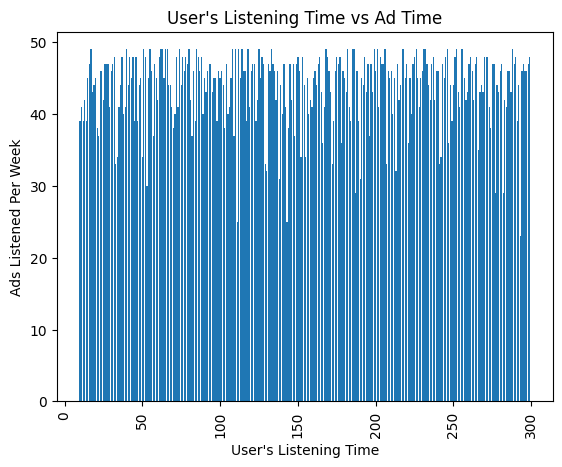

In [66]:
plt.bar(spotify['listening_time'], spotify['ads_listened_per_week']) # create a bar chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('User\'s Listening Time') # x-axis is parent's education level
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Ads Listened Per Week') # y-axis is maths score
plt.title('User\'s Listening Time vs Ad Time') # add title
plt.plot() # plot the chart to screen

As evident, those with 'Free' accounts are exposed to advertisements near-homogenously, shown by the random variability between listening time and advertisement frequency. Let us now investigate the potential correlations between any variables:

[]

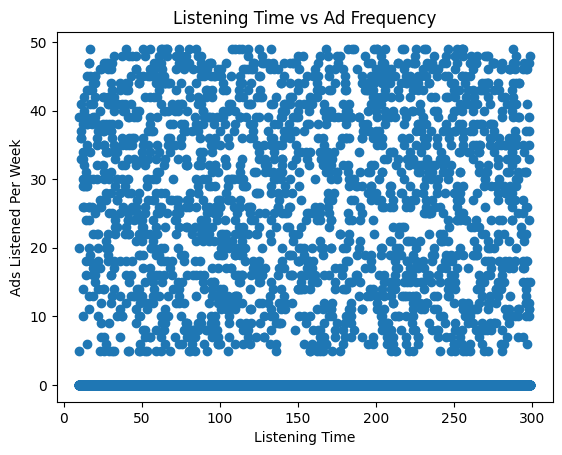

In [77]:
plt.scatter(spotify['listening_time'], spotify['ads_listened_per_week'])
plt.xlabel('Listening Time')
plt.ylabel('Ads Listened Per Week')
plt.title('Listening Time vs Ad Frequency')
plt.plot()

As demonstrated, there is no possible relationship between the two variables, thus proving its 'randomness'. However, to confirm this statistically, we will run a Pearson's Correlation Coefficient Test:

In [82]:

listening_time_vs_ad_frequency_corr_pearson = spotify['listening_time'].corr(spotify['ads_listened_per_week'], method='pearson')
print(f"Pearson Correlation (Listening Time vs. Ad Frequency): {round(listening_time_vs_ad_frequency_corr_pearson,2)}")

Pearson Correlation (Listening Time vs. Ad Frequency): 0.0


As assumed, there is no correlation.

Moving forward, let us now examine the probability distributions between these two variables:

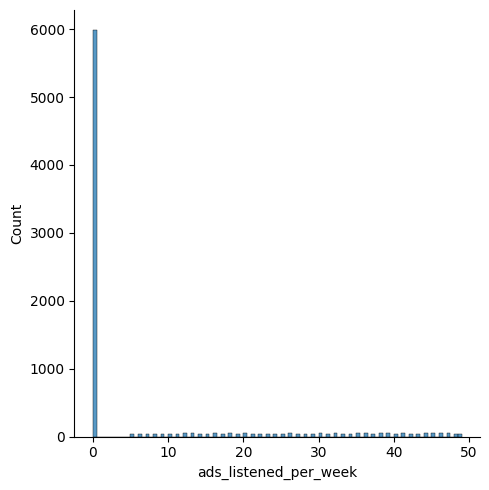

In [84]:
adprob = sns.displot(spotify['ads_listened_per_week'])

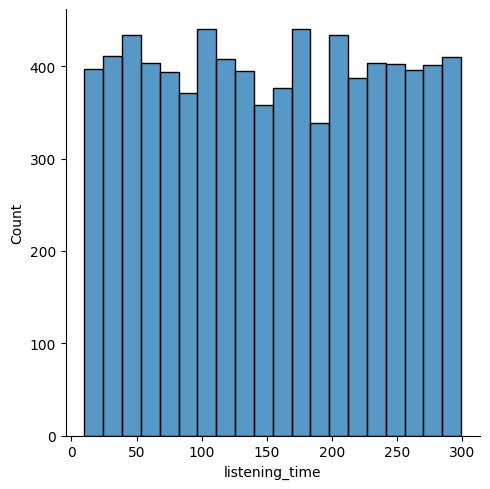

In [85]:
listeningprob = sns.displot(spotify['listening_time'])

In [86]:
print(spotify['listening_time'].describe())

count    8000.000000
mean      154.068250
std        84.015596
min        10.000000
25%        81.000000
50%       154.000000
75%       227.000000
max       299.000000
Name: listening_time, dtype: float64


In [87]:
print(spotify['ads_listened_per_week'].describe())

count    8000.000000
mean        6.943875
std        13.617953
min         0.000000
25%         0.000000
50%         0.000000
75%         5.000000
max        49.000000
Name: ads_listened_per_week, dtype: float64


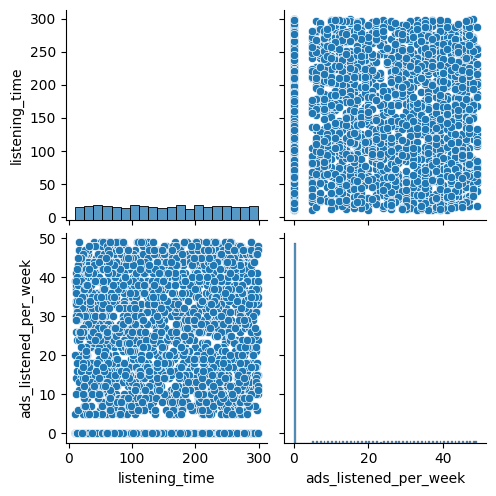

In [88]:
sns.pairplot(data = spotify[['listening_time','ads_listened_per_week']],diag_kind='hist')

Due to the total 'randomness' of both variables' distribution and correlation, let us investigate the 'why' through skewness and kurtosis analysis:

In [89]:
print("Listening Time")
print(f"Skewness Listening Time: {round(spotify['listening_time'].skew(),2)}")
print(f"Kurtosis Listening Time: {round(spotify['listening_time'].kurt(),2)}")

Listening Time
Skewness Listening Time: 0.01
Kurtosis Listening Time: -1.21


In [90]:
print("Ad Frequency")
print(f"Skewness Ad Frequency: {round(spotify['ads_listened_per_week'].skew(),2)}")
print(f"Kurtosis Ad Frequency: {round(spotify['ads_listened_per_week'].kurt(),2)}")

Ad Frequency
Skewness Ad Frequency: 1.8
Kurtosis Ad Frequency: 1.81


Therefore, Listening Time has a relatively normal skewness and is platykurtic, meaning it is thin-tailed with no probability clustering. Regarding Ad Frequency, we can observe that it is positively skewed and leptokurtic, meaning that ads listened per week are more likely to increase significantly to high levels.